In [ ]:
# ==============================================================================
# PIPELINE DE INGENIERÍA DE CARACTERÍSTICAS, SELECCIÓN Y PCA
# ==============================================================================
import os
import re
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold, f_classif
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)

# Configuración visual
%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
RANDOM_STATE = 42

In [ ]:
# --- 1. CARGA DE ARCHIVOS ---
# Los CSV deben estar en la carpeta "data/" (o junto al notebook).
DATA = Path("data") if Path("data").exists() else Path(".")

def read_csv_robust(name):
    """Lee en utf-8 y, si el archivo viene en cp1252, reintenta con esa codificación."""
    path = DATA / name
    try:
        return pd.read_csv(path, encoding="utf-8")
    except UnicodeDecodeError:
        return pd.read_csv(path, encoding="cp1252")

df_sessions = read_csv_robust('sessions_synthetic.csv')
df_segments = read_csv_robust('transcript_segments_raw.csv')
df_gold = read_csv_robust('gold_standard_synthetic.csv')
df_rag = read_csv_robust('rag_documents_synthetic.csv')

print("--- Dimensiones de los DataFrames Cargados ---")
print(f"Sessions:       {df_sessions.shape}")
print(f"Segments Raw:   {df_segments.shape}")
print(f"Gold Standard:  {df_gold.shape}")
print(f"RAG Documents: {df_rag.shape}")

--- Dimensiones de los DataFrames Cargados ---
Sessions:       (30, 8)
Segments Raw:   (141, 8)
Gold Standard:  (141, 10)
RAG Documents: (24, 6)


In [ ]:
# --- 2. CALIDAD DE DATOS (QA) ---
print("\n--- Diagnóstico de Valores Faltantes en Segmentos ---")
print(df_segments.isnull().sum())

# Mostrar nulos e inconsistencias lógicas
seg_nulo_texto = df_segments[df_segments['text_raw'].isnull()]
seg_tiempo_invalido = df_segments[df_segments['end_sec'] <= df_segments['start_sec']]
print(f"\n Segmentos con Texto Faltante detectados: {len(seg_nulo_texto)} (Ej: {seg_nulo_texto['segment_id'].tolist()})")
print(f" Segmentos con Inconsistencia de Tiempos detectados (end_sec <= start_sec): {len(seg_tiempo_invalido)} (Ej: {seg_tiempo_invalido['segment_id'].tolist()})")

# Otros problemas del corpus ampliado
txt_raw = df_segments['text_raw'].fillna('')
seg_markup = df_segments[txt_raw.str.contains(r'<[^>]+>')]
es_relleno = txt_raw.str.match(r'^Discusión técnica sobre el segmento \d+\.?$')
sesiones_sin_segmentos = sorted(set(df_sessions['session_id']) - set(df_segments['session_id']))
print(f" Segmentos con markup HTML: {len(seg_markup)} -> {seg_markup['segment_id'].tolist()}")
print(f" Segmentos sin speaker: {df_segments['speaker'].isnull().sum()} | sin speaker_role: {df_segments['speaker_role'].isnull().sum()}")
print(f" Textos repetidos (misma frase en distintos segmentos): {txt_raw[txt_raw != ''].duplicated().sum()}")
print(f" Sesiones sin ningún segmento: {sesiones_sin_segmentos}")
print(f" Segmentos de relleno ('Discusión técnica sobre el segmento N'): {es_relleno.sum()} "
      f"(IDs {df_segments.loc[es_relleno, 'segment_id'].min()}–{df_segments.loc[es_relleno, 'segment_id'].max()})")

print("\n--- Relleno vs. categoría esperada (posible efecto de lote) ---")
display(pd.crosstab(es_relleno.rename('es_relleno'), df_segments['expected_category']))

# --- Integridad relacional entre las 4 tablas
ref = df_gold['evidence_reference'].str.split('#', expand=True)
seg_to_sess = df_segments.set_index('segment_id')['session_id']
excl_ids = set(seg_nulo_texto['segment_id']) | set(seg_tiempo_invalido['segment_id'])
print("\n--- Integridad relacional ---")
print(f" Gold: {len(df_gold)} preguntas | question_id únicos: {df_gold['question_id'].is_unique} | preguntas distintas: {df_gold['question'].nunique()}")
print(f" Gold -> sesión existe: {ref[0].isin(df_sessions['session_id']).mean():.0%} | segmento existe: {ref[1].isin(df_segments['segment_id']).mean():.0%} | "
      f"segmento pertenece a esa sesión: {(ref[1].map(seg_to_sess) == ref[0]).mean():.0%}")
print(f" Gold que apuntan a segmentos excluidos ({sorted(excl_ids)}): {ref[1].isin(excl_ids).sum()}")
print(f" Gold sin reviewer: {df_gold['reviewer'].isnull().sum()} | categorías de gold: {df_gold['category'].nunique()} (segmentos: {df_segments['expected_category'].nunique()})")
print(f" Longitud de las preguntas: min {df_gold['question'].str.len().min()} / max {df_gold['question'].str.len().max()} caracteres (plantilla)")
print(f" RAG: {df_rag['status'].value_counts().to_dict()} | duplicados declarados: {df_rag['duplicate_of'].notna().sum()}")
print(f" Segmentos por partición: {df_segments.merge(df_sessions, on='session_id')['dataset_split'].value_counts().to_dict()}")


--- Diagnóstico de Valores Faltantes en Segmentos ---
session_id           0
segment_id           0
start_sec            0
end_sec              0
speaker              4
speaker_role         3
expected_category    0
text_raw             1
dtype: int64

 Segmentos con Texto Faltante detectados: 1 (Ej: ['SEG028'])
 Segmentos con Inconsistencia de Tiempos detectados (end_sec <= start_sec): 1 (Ej: ['SEG017'])
 Segmentos con markup HTML: 3 -> ['SEG008', 'SEG075', 'SEG086']
 Segmentos sin speaker: 4 | sin speaker_role: 3
 Textos repetidos (misma frase en distintos segmentos): 35
 Sesiones sin ningún segmento: ['S06_HANDOVER']
 Segmentos de relleno ('Discusión técnica sobre el segmento N'): 28 (IDs SEG001–SEG030)

--- Relleno vs. categoría esperada (posible efecto de lote) ---


expected_category,architecture_decision,database_migration,next_steps,requirement,technical_discussion
es_relleno,,,,,
False,6,17,43,34,13
True,0,0,18,10,0



--- Integridad relacional ---
 Gold: 141 preguntas | question_id únicos: True | preguntas distintas: 141
 Gold -> sesión existe: 100% | segmento existe: 100% | segmento pertenece a esa sesión: 100%
 Gold que apuntan a segmentos excluidos (['SEG017', 'SEG028']): 2
 Gold sin reviewer: 2 | categorías de gold: 2 (segmentos: 5)
 Longitud de las preguntas: min 61 / max 61 caracteres (plantilla)
 RAG: {'ready': 23, 'empty': 1} | duplicados declarados: 1
 Segmentos por partición: {'development': 89, 'validation': 41, 'test': 11}


In [ ]:
# --- 3. PREPROCESAMIENTO Y LIMPIEZA ---
def clean_html_tags(text):
    if not isinstance(text, str):
        return text
    clean_text = re.sub(r'<[^>]+>', ' ', text)
    clean_text = re.sub(r'\s+', ' ', clean_text).strip()
    return clean_text

# Excluir justificadamente SEG017 y SEG028 (se conserva una copia para trazabilidad)
valid_mask = ~(df_segments['text_raw'].isnull() | (df_segments['end_sec'] <= df_segments['start_sec']))
df_segments_excluded = df_segments[~valid_mask].copy()
df_segments_clean = df_segments[valid_mask].copy()

# Bandera previa a la imputación: que el speaker falte también es información
df_segments_clean['speaker_unknown'] = df_segments_clean['speaker'].isnull().astype(int)

# Imputar nulos categóricos nominales (UNKNOWN para no perder texto de conversación)
df_segments_clean['speaker'] = df_segments_clean['speaker'].fillna('UNKNOWN_SPEAKER')
df_segments_clean['speaker_role'] = df_segments_clean['speaker_role'].fillna('UNKNOWN_ROLE')

# Limpiar HTML (se conserva la bandera de que el segmento traía markup)
df_segments_clean['has_markup'] = df_segments_clean['text_raw'].str.contains(r'<[^>]+>').astype(int)
df_segments_clean['text_clean'] = df_segments_clean['text_raw'].apply(clean_html_tags)

print(f"\nSegmentos originales: {len(df_segments)} -> Válidos post-calidad: {len(df_segments_clean)}")
print(f"Filas excluidas: {len(df_segments_excluded)} ({', '.join(df_segments_excluded['segment_id'])}).")

print("\n--- Antes / después de la limpieza de markup ---")
display(df_segments_clean.loc[df_segments_clean['has_markup'] == 1, ['segment_id', 'text_raw', 'text_clean']])

# Los textos repetidos NO se eliminan: son segmentos distintos (otra sesión / otro instante) y
# el corpus es sintético con plantillas; se conservan y se controlan con la partición por sesión.
print(f"Textos repetidos conservados: {df_segments_clean['text_clean'].duplicated().sum()}")

# --- Verificaciones (si alguna falla, el notebook se detiene) ---
assert set(df_segments_excluded['segment_id']) == {'SEG017', 'SEG028'}, "Exclusiones inesperadas"
assert len(df_segments_clean) + len(df_segments_excluded) == len(df_segments)
assert df_segments_clean['segment_id'].is_unique
assert not df_segments_clean['text_clean'].str.contains(r'<[^>]+>').any(), "Quedó markup"
assert df_segments_clean[['speaker', 'speaker_role', 'text_clean']].notna().all().all()
print("✔ Verificaciones de limpieza superadas")


Segmentos originales: 141 -> Válidos post-calidad: 139
Filas excluidas: 2 (SEG017, SEG028).

--- Antes / después de la limpieza de markup ---


,segment_id,text_raw,text_clean
7,SEG008,<i>La arquitectura utilizará almacenamiento de...,La arquitectura utilizará almacenamiento de ob...
74,SEG075,<i>The Golden Dataset for evaluation must cont...,The Golden Dataset for evaluation must contain...
85,SEG086,I will share the architecture slides<br>with A...,I will share the architecture slides with Aaro...


Textos repetidos conservados: 36
✔ Verificaciones de limpieza superadas


In [ ]:
# --- 4. INGENIERÍA DE CARACTERÍSTICAS ---
# Unión relacional (cada segmento pertenece a una sesión)
df_merged = pd.merge(df_segments_clean, df_sessions, on='session_id', how='inner', validate='many_to_one')
assert len(df_merged) == len(df_segments_clean), "La unión perdió segmentos"
df_merged = df_merged.sort_values(['session_id', 'start_sec']).reset_index(drop=True)

# Extracción de variables numéricas complejas
df_merged['segment_duration_sec'] = df_merged['end_sec'] - df_merged['start_sec']
df_merged['text_length'] = df_merged['text_clean'].apply(len)
df_merged['word_count'] = df_merged['text_clean'].apply(lambda x: len(x.split()))
df_merged['avg_word_length'] = df_merged['text_length'] / (df_merged['word_count'] + 1e-5)

# --- Nuevas características (conocimiento del dominio: reuniones GSD) ---
grp = df_merged.groupby('session_id')
n_seg = grp['segment_id'].transform('size')
# Posición relativa del segmento dentro de su sesión (0 = inicio, 1 = cierre): los acuerdos y
# siguientes pasos tienden a aparecer al final de la reunión.
df_merged['rel_pos'] = grp.cumcount() / (n_seg - 1).clip(lower=1)
# Pausa respecto al segmento anterior de la misma sesión (0 en el primero)
df_merged['gap_prev_sec'] = (df_merged['start_sec'] - grp['end_sec'].shift(1)).fillna(0)

txt = df_merged['text_clean'].str.lower()
df_merged['is_placeholder'] = txt.str.match(r'^discusión técnica sobre el segmento \d+\.?$').astype(int)
real = df_merged['is_placeholder'] == 0   # los indicadores léxicos solo aplican a texto real
# Señales léxicas (hipótesis de dominio, no etiquetas): requisitos -> obligación/umbral;
# siguientes pasos -> compromiso/acción; decisiones de arquitectura -> pregunta/propuesta.
df_merged['has_obligation'] = (txt.str.contains(r'\b(?:must|requires?|required|requirement|requirements|at least|shall)\b') & real).astype(int)
df_merged['has_commitment'] = (txt.str.contains(r"\b(?:i will|i'm going to|let's|next step|schedule|we should)\b") & real).astype(int)
df_merged['has_number'] = (txt.str.contains(r'\d') & real).astype(int)
df_merged['has_question'] = txt.str.contains(r'\?').astype(int)
TECH_TERMS = ['bigquery', 'spanner', 'dataflow', 'pub/sub', 'cloud', 'vertex', 'gemini', 'sql', 'database',
              'pipeline', 'ci/cd', 'debezium', 'dms', 'llm', 'embedding', 'latency', 'schema', 'dashboard']
df_merged['tech_term_count'] = txt.apply(lambda x: sum(t in x for t in TECH_TERMS))

# --- Codificación ---
# Ordinal: project_phase sigue el ciclo de vida del proyecto (hay orden natural)
PHASE_ORDER = ['Discovery', 'Architecture', 'Security', 'Implementation', 'Review / Next Steps', 'Handover']
df_merged['phase_ord'] = df_merged['project_phase'].map({p: i for i, p in enumerate(PHASE_ORDER)})
assert df_merged['phase_ord'].notna().all(), "Fase sin mapear"
# Binarias de sesión
df_merged['video_webm'] = (df_merged['video_format'] == 'WEBM').astype(int)
df_merged['has_audio'] = df_merged['has_audio'].astype(int)
df_merged['has_transcript'] = df_merged['has_transcript'].astype(int)

# Variable objetivo: se separa y NO se usa como característica
y = df_merged['expected_category']

# One-Hot solo para la nominal speaker_role (sin orden entre roles)
df_encoded = pd.get_dummies(df_merged, columns=['speaker_role'], drop_first=False, dtype=int)

# Grupos de columnas
num_cols = ['start_sec', 'end_sec', 'segment_duration_sec', 'text_length', 'word_count',
            'avg_word_length', 'duration_min', 'num_speakers']            # originales
new_num_cols = ['rel_pos', 'gap_prev_sec', 'tech_term_count']            # nuevas numéricas
ord_cols = ['phase_ord']
role_cols = [c for c in df_encoded.columns if c.startswith('speaker_role_')]
bin_cols = ['speaker_unknown', 'has_markup', 'has_obligation', 'has_commitment', 'has_number',
            'has_question', 'has_audio', 'has_transcript', 'video_webm'] + role_cols
cand_num = num_cols + new_num_cols + ord_cols

print("✅ Ingeniería de Características finalizada.")
print(f"Dimensiones de la matriz integrada para modelado: {df_encoded.shape}")
print(f"Candidatas: {len(cand_num)} numéricas/ordinales + {len(bin_cols)} binarias ({len(role_cols)} de ellas por one-hot de speaker_role)")
print(f"Objetivo: expected_category -> {y.value_counts().to_dict()}")
display(df_merged[['segment_id', 'rel_pos', 'gap_prev_sec', 'has_obligation', 'has_commitment', 'has_number',
                   'has_question', 'tech_term_count', 'phase_ord']].head(6))

✅ Ingeniería de Características finalizada.
Dimensiones de la matriz integrada para modelado: (139, 40)
Candidatas: 12 numéricas/ordinales + 18 binarias (9 de ellas por one-hot de speaker_role)
Objetivo: expected_category -> {'next_steps': 59, 'requirement': 44, 'database_migration': 17, 'technical_discussion': 13, 'architecture_decision': 6}


,segment_id,rel_pos,gap_prev_sec,has_obligation,has_commitment,has_number,has_question,tech_term_count,phase_ord
0,SEG005,0.0,0.0,0,0,0,0,0,0
1,SEG001,0.2,60.0,0,0,0,0,0,0
2,SEG006,0.4,-20.0,0,0,0,0,0,0
3,SEG002,0.6,60.0,0,0,0,0,0,0
4,SEG003,0.8,60.0,0,0,0,0,0,0
5,SEG004,1.0,60.0,0,0,0,0,0,0


### **Justificación de las Decisiones de Construcción de Características**

Para cumplir con la fase de ingeniería de características bajo la metodología **CRISP-ML(Q)**, se diseñaron variables derivadas con valor semántico para modelar las interacciones técnicas de GSD LATAM. Se conservan las del notebook original y se agregan las marcadas con (nueva).

1. **`segment_duration_sec` (`end_sec - start_sec`):** duración neta de cada intervención.
2. **`text_length` y `word_count`:** volumen conversacional; aproximan la densidad informativa del segmento y, más adelante, el presupuesto de contexto del RAG.
3. **`avg_word_length`:** complejidad léxica aproximada (palabras largas suelen ser términos técnicos).
4. **`rel_pos` (nueva):** posición del segmento dentro de su sesión (0 = inicio, 1 = cierre). Se usa posición relativa y no segundos absolutos porque las sesiones duran entre 17 y 60 minutos; en reuniones GSD los acuerdos y siguientes pasos tienden a ir al final.
5. **`gap_prev_sec` (nueva):** pausa respecto al segmento anterior de la misma sesión (negativa si se solapan). Aproxima el ritmo de la conversación.
6. **`has_obligation`, `has_commitment`, `has_number`, `has_question` (nuevas):** indicadores léxicos con base en el dominio. Un requisito se expresa con "must / requires / at least", un siguiente paso con "I will / let's / schedule / next step", y una decisión de arquitectura suele formularse como pregunta o propuesta. Son hipótesis a contrastar con las pruebas de la sección 6, no etiquetas. Solo se calculan sobre texto real (no sobre el relleno).
7. **`tech_term_count` (nueva):** conteo de términos de nube y datos (BigQuery, Spanner, Dataflow, SQL, pipeline…), medida de densidad técnica.
8. **`speaker_unknown` (nueva):** conserva el hecho de que el speaker faltaba antes de imputar `UNKNOWN_SPEAKER`; la ausencia de speaker puede ser información y no solo un hueco.
9. **`is_placeholder` (nueva, solo diagnóstico):** marca los 27 segmentos válidos con el texto de relleno "Discusión técnica sobre el segmento N" (SEG001–SEG030). Son un efecto de lote del corpus (otro idioma, otra plantilla, solo dos categorías), por eso no entra como característica y esos segmentos no participan en el ajuste de ningún paso.

**Codificación categórica**
- **`project_phase` → ordinal (`phase_ord`):** las 6 fases siguen el ciclo de vida del proyecto (Discovery → … → Handover), por lo que existe un orden natural y una sola columna conserva esa información.
- **`speaker_role` → One-Hot:** son roles nominales sin orden; el one-hot evita imponer una jerarquía artificial. Se deja `drop_first=False` porque la selección posterior descarta columnas redundantes.
- **`expected_category` → variable objetivo:** en la versión anterior se codificaba como característica y a la vez se usaba para colorear el PCA. Eso es **fuga de información**; ahora se separa como `y` y solo se usa para evaluar asociaciones y graficar.
- **`has_audio`, `has_transcript`, `video_format`:** se convierten a binarias (0/1) para poder evaluar su varianza.


Segmentos -> development: 88 | validation: 40 | test: 11 | relleno: 27
Conjunto de ajuste (development sin relleno): 66 segmentos de 16 sesiones

--- Análisis de Asimetría (Skewness) ---
                      skew_todos  skew_ajuste
start_sec                  0.360        0.456
end_sec                    0.436        0.413
segment_duration_sec       0.399        0.222
text_length               -1.151       -0.836
word_count                -0.943       -1.238
avg_word_length            1.156        1.264
duration_min               0.273        0.356
num_speakers               0.146       -0.389
rel_pos                    0.000       -0.030
gap_prev_sec               2.187        0.963
tech_term_count            1.267        1.049
phase_ord                  0.145       -0.023

--- Yeo-Johnson (ajustado solo con el conjunto de ajuste) ---


,variable,skew_antes,lambda,skew_despues,aplicada
0,text_length,-0.836,2.459,0.136,True
1,word_count,-1.238,2.809,0.026,True
2,avg_word_length,1.264,-3.682,0.045,True
3,gap_prev_sec,0.963,0.480,-0.244,True
4,tech_term_count,1.049,-0.319,0.074,True


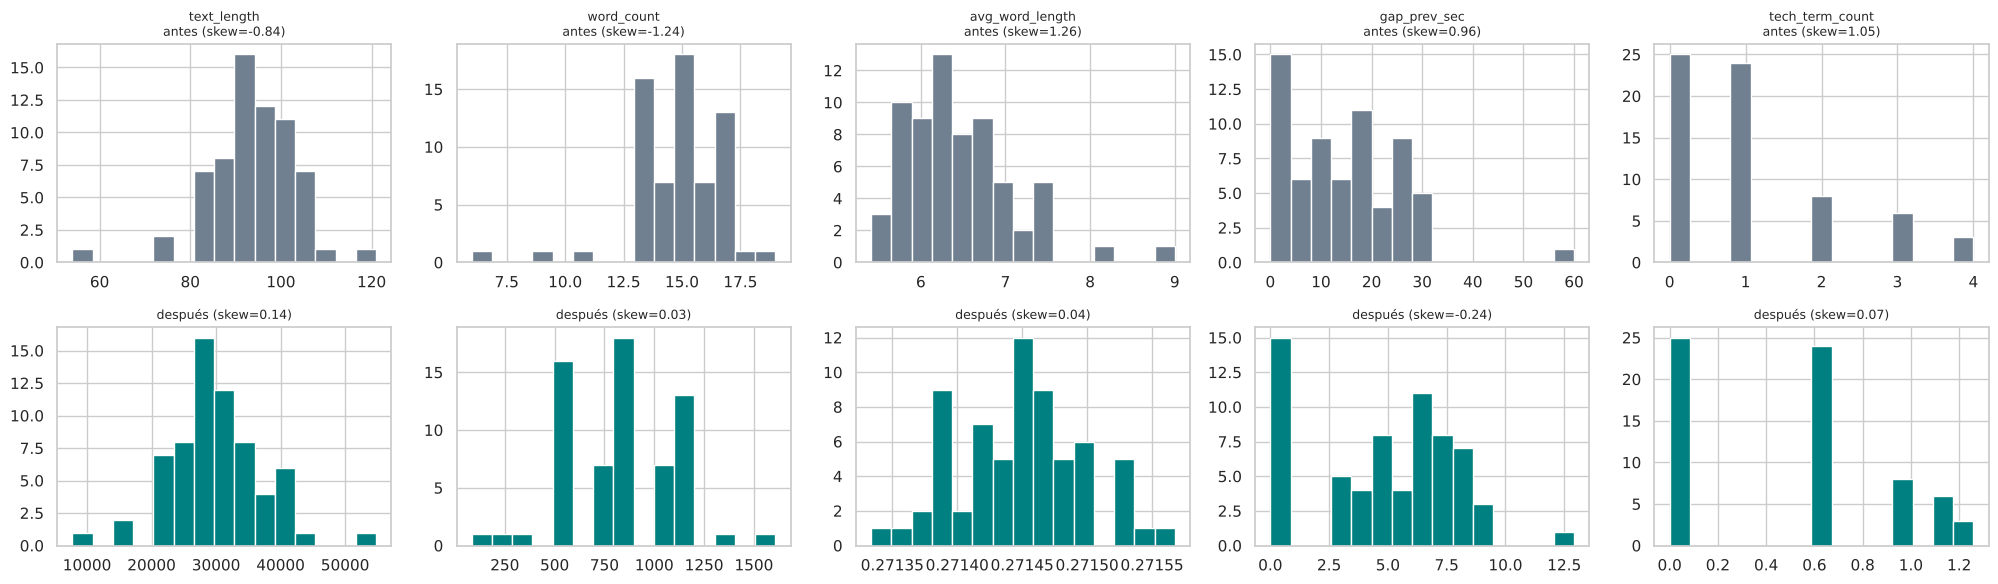


Media / desviación en el conjunto de ajuste (debe ser 0 / 1): 0.0 / [1.]


In [ ]:
# --- 5. NORMALIZACIÓN Y ANÁLISIS DE ASIMETRÍA ---
# Particiones definidas en sessions.dataset_split (a nivel de sesión, así no se mezclan segmentos de una misma reunión)
dev = (df_encoded['dataset_split'] == 'development').values
val = (df_encoded['dataset_split'] == 'validation').values
tst = (df_encoded['dataset_split'] == 'test').values
placeholder = (df_encoded['is_placeholder'] == 1).values
# Conjunto de AJUSTE: development sin los segmentos de relleno (sin contenido semántico, efecto de lote).
# Todo lo que se "aprende" (Yeo-Johnson, escalador, filtros, PCA) se ajusta solo aquí.
train = dev & ~placeholder
print(f"Segmentos -> development: {dev.sum()} | validation: {val.sum()} | test: {tst.sum()} | relleno: {placeholder.sum()}")
print(f"Conjunto de ajuste (development sin relleno): {train.sum()} segmentos de {df_encoded.loc[train, 'session_id'].nunique()} sesiones")

skewness = pd.DataFrame({'skew_todos': df_encoded[cand_num].skew(),
                         'skew_ajuste': df_encoded.loc[train, cand_num].skew()})
print("\n--- Análisis de Asimetría (Skewness) ---")
print(skewness.round(3))

# Yeo-Johnson solo donde |skew| > 0.5 (asimetría moderada) y se conserva únicamente si reduce |skew|
SKEW_THR = 0.5
df_tr = df_encoded[cand_num].astype(float).copy()
yj_rows = []
for col in cand_num:
    s_b = skewness.loc[col, 'skew_ajuste']
    if not (abs(s_b) > SKEW_THR) or df_encoded.loc[train, col].nunique() <= 2:
        continue
    pt = PowerTransformer(method='yeo-johnson', standardize=False).fit(df_tr.loc[train, [col]])
    nuevo = pt.transform(df_tr[[col]]).ravel()
    s_a = pd.Series(nuevo[train]).skew()
    aplicar = abs(s_a) < abs(s_b)
    if aplicar:
        df_tr[col] = nuevo
    yj_rows.append({'variable': col, 'skew_antes': s_b, 'lambda': pt.lambdas_[0], 'skew_despues': s_a,
                    'aplicada': aplicar})
yj_table = pd.DataFrame(yj_rows)
print("\n--- Yeo-Johnson (ajustado solo con el conjunto de ajuste) ---")
display(yj_table.round(3) if len(yj_table) else "Ninguna variable superó el umbral")

if len(yj_table):
    fig, axes = plt.subplots(2, len(yj_table), figsize=(4 * len(yj_table), 6), squeeze=False)
    for j, r in yj_table.iterrows():
        axes[0, j].hist(df_encoded.loc[train, r['variable']], bins=15, color='slategray')
        axes[0, j].set_title(f"{r['variable']}\nantes (skew={r['skew_antes']:.2f})", fontsize=9)
        axes[1, j].hist(df_tr.loc[train, r['variable']], bins=15, color='teal')
        axes[1, j].set_title(f"después (skew={r['skew_despues']:.2f})" + ("" if r['aplicada'] else " - NO aplicada"), fontsize=9)
    plt.tight_layout(); plt.show()

# Normalización (z-score) ajustada SOLO con el conjunto de ajuste y aplicada a todos los segmentos
scaler = StandardScaler().fit(df_tr.loc[train])
X_scaled = scaler.transform(df_tr)
df_scaled = pd.DataFrame(X_scaled, columns=cand_num, index=df_encoded.index)
print("\nMedia / desviación en el conjunto de ajuste (debe ser 0 / 1):",
      df_scaled.loc[train].mean().abs().max().round(6), "/", df_scaled.loc[train].std(ddof=0).round(3).unique())

### **Justificación de las Técnicas de Normalización y Escalamiento**

1. **Partición antes de aprender nada:** `sessions.dataset_split` ya separa por sesión (development / validation / test), así que ningún segmento de una reunión cae en dos particiones. Todo lo que se ajusta (Yeo-Johnson, escalador, filtros y PCA) usa solo el conjunto de ajuste: **66 segmentos de 16 sesiones** (development sin los segmentos de relleno). Validation y test solo se transforman con esos parámetros, para evitar fuga de datos.

2. **Análisis de asimetría (skewness) y transformación:** con el umbral habitual |skew| > 0.5, cinco variables se alejan de la simetría en el conjunto de ajuste. La versión anterior concluyó "no transformar", pero eso no se sostiene con el corpus ampliado:

   | Variable | Skew antes | Skew después (Yeo-Johnson) |
   |---|---|---|
   | `text_length` | -0.84 | 0.14 |
   | `word_count` | -1.24 | 0.03 |
   | `avg_word_length` | 1.26 | 0.05 |
   | `gap_prev_sec` | 0.96 | -0.24 |
   | `tech_term_count` | 1.05 | 0.07 |

   Se eligió **Yeo-Johnson** y no logaritmo o Box-Cox porque `gap_prev_sec` toma valores cero y negativos (solapamientos) y `tech_term_count` tiene ceros; Box-Cox y el logaritmo exigen valores estrictamente positivos. Cada transformación solo se conserva si reduce |skew| (en las cinco ocurrió). Las variables con |skew| ≤ 0.5 (`start_sec`, `end_sec`, `segment_duration_sec`, `duration_min`, `num_speakers`, `rel_pos`, `phase_ord`) no se transforman: ya son aproximadamente simétricas.

3. **StandardScaler (z-score):** las variables están en escalas muy distintas (segundos hasta ~1 000, número de participantes de 2 a 6). Sin escalar, las de mayor magnitud dominarían la varianza del PCA y las distancias de modelos como k-NN o SVM. Se eligió z-score y no Min-Max porque, tras Yeo-Johnson, no quedan colas extremas que Min-Max comprimiría, y porque el PCA trabaja con varianzas. Las variables binarias no se escalan: ya están en {0, 1}.

4. **Límite:** `duration_min` y `num_speakers` son atributos de la **sesión** y se repiten en todos sus segmentos. Su variabilidad efectiva es la de 16 sesiones, no la de 66 segmentos.


## **Selección de características (métodos de filtrado)**

Se aplican cuatro filtros en secuencia sobre las 30 candidatas (12 numéricas/ordinales y 18 binarias): umbral de varianza, ANOVA, chi-cuadrado y correlación. Todos se calculan en el conjunto de ajuste.

In [ ]:
# --- 6. SELECCIÓN DE CARACTERÍSTICAS (MÉTODOS DE FILTRADO) ---
# 6.1 Umbral de varianza -------------------------------------------------------
VAR_THR = 0.02   # en una binaria 0/1, var = p(1-p) <= 0.02 equivale a que el valor "1" aparece en < ~2 % de los segmentos
vt = VarianceThreshold(threshold=VAR_THR).fit(df_encoded.loc[train, bin_cols])
var_bin = pd.Series(vt.variances_, index=bin_cols)
drop_var = list(var_bin.index[var_bin <= VAR_THR])
const_num = [col for col in cand_num if df_encoded.loc[train, col].nunique() <= 1]
print(f"Binarias con varianza <= {VAR_THR} (se descartan): {drop_var}")
print(f"Numéricas constantes (se descartan): {const_num}")
display(var_bin.sort_values().head(10).round(4).to_frame('varianza'))

# 6.2 ANOVA (numéricas/ordinal) y chi-cuadrado (binarias) contra el objetivo ---------------------
def bh_qvalues(p):
    """Ajuste de Benjamini-Hochberg (FDR) para controlar falsos positivos por pruebas múltiples."""
    p = np.asarray(p, dtype=float); q = np.full_like(p, np.nan)
    ok = ~np.isnan(p); pv = p[ok]; order = np.argsort(pv); n = len(pv)
    adj = pv[order] * n / (np.arange(n) + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(adj, 1.0); q[ok] = out
    return q

def assoc_table(mask):
    """Asociación de cada candidata con expected_category dentro de las filas de `mask`."""
    ym = y[mask]; k = ym.nunique(); n = int(mask.sum()); rows = []
    for col in [c_ for c_ in cand_num if c_ not in const_num]:
        x = df_scaled.loc[mask, col]
        F, p = f_classif(x.to_frame(), ym)
        F, p = F[0], p[0]
        eta2 = F * (k - 1) / (F * (k - 1) + (n - k)) if np.isfinite(F) else np.nan
        rows.append({'variable': col, 'prueba': 'ANOVA', 'estadistico': F, 'p': p, 'tam_efecto': eta2, 'celdas_esp<5_%': np.nan})
    for col in [c_ for c_ in bin_cols if c_ not in drop_var]:
        ct = pd.crosstab(df_encoded.loc[mask, col], ym)
        if ct.shape[0] < 2:
            continue
        chi2_, p, dof, exp = stats.chi2_contingency(ct)
        v = np.sqrt(chi2_ / (n * min(ct.shape[0] - 1, ct.shape[1] - 1)))
        rows.append({'variable': col, 'prueba': 'chi2', 'estadistico': chi2_, 'p': p, 'tam_efecto': v,
                     'celdas_esp<5_%': (exp < 5).mean() * 100})
    t = pd.DataFrame(rows)
    t['q_BH'] = bh_qvalues(t['p'].values)
    return t.sort_values('p').reset_index(drop=True)

assoc = assoc_table(train)
assoc_all = assoc_table(dev)    # robustez: ¿cambia si se incluyen los segmentos de relleno?
print("\n--- Asociación con expected_category (conjunto de ajuste; tam_efecto = eta² para ANOVA, V de Cramér para chi²) ---")
display(assoc.round(4))
print("Cuántas pruebas chi² tienen más de 20 % de celdas con frecuencia esperada < 5:",
      int((assoc['celdas_esp<5_%'] > 20).sum()), "de", int((assoc['prueba'] == 'chi2').sum()))

Binarias con varianza <= 0.02 (se descartan): ['speaker_unknown', 'has_question', 'has_audio', 'has_transcript', 'speaker_role_UNKNOWN_ROLE', 'speaker_role_client', 'speaker_role_consultant']
Numéricas constantes (se descartan): []


,varianza
has_audio,0.0000
has_transcript,0.0000
has_question,0.0000
speaker_role_client,0.0000
speaker_role_consultant,0.0149
speaker_unknown,0.0149
speaker_role_UNKNOWN_ROLE,0.0149
has_markup,0.0294
speaker_role_Product Owner,0.0948
speaker_role_Delivery Lead,0.1065



--- Asociación con expected_category (conjunto de ajuste; tam_efecto = eta² para ANOVA, V de Cramér para chi²) ---


,variable,prueba,estadistico,p,tam_efecto,celdas_esp<5_%,q_BH
0,has_obligation,chi2,51.2172,0.0000,0.8809,60.0,0.0000
1,has_commitment,chi2,35.9726,0.0000,0.7383,40.0,0.0000
2,has_number,chi2,27.0046,0.0000,0.6397,40.0,0.0002
3,tech_term_count,ANOVA,5.7506,0.0005,0.2738,NaN,0.0031
4,duration_min,ANOVA,2.7735,0.0348,0.1539,NaN,0.1602
5,phase_ord,ANOVA,1.5086,0.2109,0.0900,NaN,0.6795
6,text_length,ANOVA,1.4367,0.2327,0.0861,NaN,0.6795
7,speaker_role_Senior Data Engineer,chi2,5.5386,0.2364,0.2897,60.0,0.6795
8,avg_word_length,ANOVA,1.3238,0.2713,0.0799,NaN,0.6932
9,speaker_role_Delivery Lead,chi2,4.0921,0.3937,0.2490,60.0,0.8901


Cuántas pruebas chi² tienen más de 20 % de celdas con frecuencia esperada < 5: 11 de 11


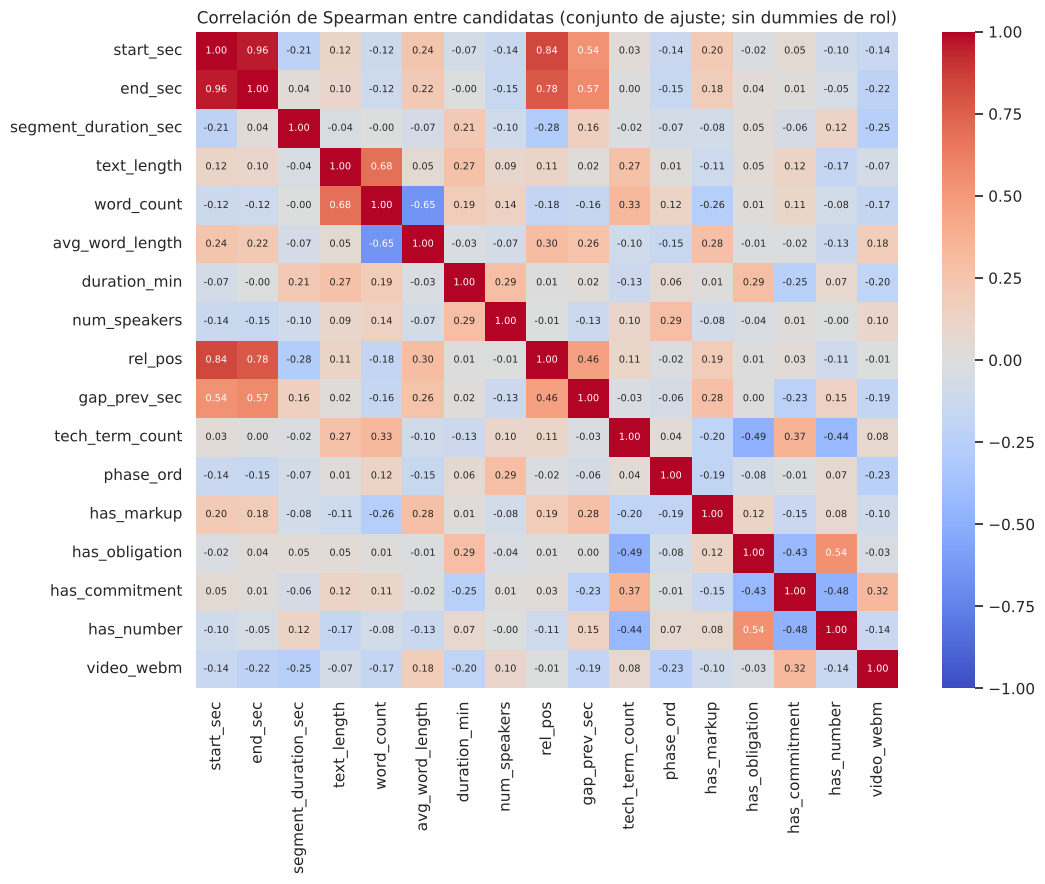

Pares con |rho| > 0.85: 1 -> se elimina la de menor asociación con el objetivo de cada par


,a,b,rho
1,start_sec,end_sec,0.96



Candidatas: 30 -> Seleccionadas: 4 (1 numéricas/ordinales, 3 binarias)


,variable,decision,motivo
0,avg_word_length,descartada,sin asociación con el objetivo (q_BH=0.693)
1,duration_min,descartada,sin asociación con el objetivo (q_BH=0.160)
2,end_sec,descartada,sin asociación con el objetivo (q_BH=0.987)
3,gap_prev_sec,descartada,sin asociación con el objetivo (q_BH=0.987)
4,has_audio,descartada,varianza <= 0.02
5,has_markup,descartada,sin asociación con el objetivo (q_BH=0.987)
6,has_question,descartada,varianza <= 0.02
7,has_transcript,descartada,varianza <= 0.02
8,num_speakers,descartada,sin asociación con el objetivo (q_BH=0.928)
9,phase_ord,descartada,sin asociación con el objetivo (q_BH=0.680)



Variables que entran al PCA (sin constantes ni redundantes): ['end_sec', 'segment_duration_sec', 'text_length', 'word_count', 'avg_word_length', 'duration_min', 'num_speakers', 'rel_pos', 'gap_prev_sec', 'tech_term_count', 'phase_ord']

--- Robustez frente al efecto de lote (seleccionadas) ---


,variable,q_BH_sin_relleno,q_BH_con_relleno
0,has_obligation,0.0000,0.0000
1,has_commitment,0.0000,0.0008
2,has_number,0.0002,0.0003
3,tech_term_count,0.0031,0.0001


In [ ]:
# 6.3 Correlación entre candidatas (redundancia) y selección final ---------------------------------
CORR_THR = 0.85
FDR_THR = 0.05
keep0 = [col for col in cand_num + bin_cols if col not in drop_var and col not in const_num]
Z = pd.concat([df_scaled, df_encoded[bin_cols]], axis=1).loc[train, keep0]
corr = Z.corr(method='spearman')

plt.figure(figsize=(11, 9))
sns.heatmap(corr.loc[[c_ for c_ in keep0 if c_ not in role_cols], [c_ for c_ in keep0 if c_ not in role_cols]],
            cmap='coolwarm', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Correlación de Spearman entre candidatas (conjunto de ajuste; sin dummies de rol)')
plt.tight_layout(); plt.show()

score = assoc.set_index('variable')['p'].reindex(keep0).fillna(1.0)       # menor p = más informativa
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename('rho').reset_index().rename(columns={'level_0': 'a', 'level_1': 'b'}))
pairs = pairs[pairs['rho'].abs() > CORR_THR].sort_values('rho', key=abs, ascending=False)
drop_corr, motivo = set(), {}
for _, r in pairs.iterrows():
    if r['a'] in drop_corr or r['b'] in drop_corr:
        continue
    peor, mejor = (r['a'], r['b']) if score[r['a']] > score[r['b']] else (r['b'], r['a'])
    drop_corr.add(peor); motivo[peor] = f"redundante con {mejor} (rho={r['rho']:.2f})"
print(f"Pares con |rho| > {CORR_THR}: {len(pairs)} -> se elimina la de menor asociación con el objetivo de cada par")
display(pairs.round(3).head(15))

# Reglas de decisión por variable
q = assoc.set_index('variable')['q_BH']
decision = []
for col in cand_num + bin_cols:
    if col in const_num:   d, m = 'descartada', 'constante'
    elif col in drop_var:  d, m = 'descartada', f'varianza <= {VAR_THR}'
    elif col in drop_corr: d, m = 'descartada', motivo[col]
    elif not (q.get(col, 1.0) < FDR_THR): d, m = 'descartada', f'sin asociación con el objetivo (q_BH={q.get(col, np.nan):.3f})'
    else:                  d, m = 'SELECCIONADA', f'q_BH={q[col]:.4f}'
    decision.append({'variable': col, 'decision': d, 'motivo': m})
decision = pd.DataFrame(decision)
sel_num = [v for v in decision.loc[decision.decision == 'SELECCIONADA', 'variable'] if v in cand_num]
sel_bin = [v for v in decision.loc[decision.decision == 'SELECCIONADA', 'variable'] if v in bin_cols]
print(f"\nCandidatas: {len(cand_num) + len(bin_cols)} -> Seleccionadas: {len(sel_num) + len(sel_bin)} "
      f"({len(sel_num)} numéricas/ordinales, {len(sel_bin)} binarias)")
display(decision.sort_values(['decision', 'variable'], ascending=[False, True]).reset_index(drop=True))

# Reserva para PCA: continuas/ordinales que superan varianza y redundancia (el PCA es no supervisado,
# por eso NO se filtra por asociación con el objetivo)
pca_pool = [v for v in cand_num if v not in const_num and v not in drop_corr]
print(f"\nVariables que entran al PCA (sin constantes ni redundantes): {pca_pool}")

# Robustez: la misma asociación incluyendo los segmentos de relleno
rob = assoc[['variable', 'q_BH']].merge(assoc_all[['variable', 'q_BH']], on='variable', suffixes=('_sin_relleno', '_con_relleno'))
print("\n--- Robustez frente al efecto de lote (seleccionadas) ---")
display(rob[rob['variable'].isin(sel_num + sel_bin)].round(4))

### **Justificación de los métodos de selección y resultados**

1. **Umbral de varianza (0.02):** una binaria con varianza ≤ 0.02 tiene el valor "1" en menos de ~2 % de los segmentos, así que casi no distingue nada. Se descartaron 7 variables: `has_audio` y `has_transcript` (constantes tras la unión), `has_question` y `speaker_role_client` (varianza cero en el conjunto de ajuste), y `speaker_unknown`, `speaker_role_UNKNOWN_ROLE` y `speaker_role_consultant` (un solo caso cada una).
2. **Correlación (Spearman, |ρ| > 0.85):** solo hay un par redundante, `start_sec` y `end_sec` (ρ = 0.96); se elimina `start_sec`, la menos asociada con el objetivo. Spearman evita suponer linealidad. `rel_pos` y `end_sec` también se correlacionan (0.78), pero por debajo del umbral y miden cosas distintas (posición relativa y tiempo absoluto), así que se conservan.
3. **ANOVA (numéricas) y chi-cuadrado (binarias) contra `expected_category`:** miden si la variable distingue las clases. Se controlan las pruebas múltiples con el ajuste **Benjamini-Hochberg (q < 0.05)**. Quedan **4 de 30**:
   - `has_obligation` (chi² = 51.2, V de Cramér = 0.88)
   - `has_commitment` (chi² = 36.0, V = 0.74)
   - `has_number` (chi² = 27.0, V = 0.64)
   - `tech_term_count` (ANOVA F = 5.75, η² = 0.27)

   Las variables de forma y de contexto (`text_length`, `word_count`, `rel_pos`, `phase_ord`, rol del hablante, formato de video…) no distinguen las categorías. `duration_min` tiene p = 0.035 sin ajustar, pero q = 0.16, y no se selecciona.
4. **Robustez frente al efecto de lote:** las 4 seleccionadas siguen siendo significativas (q ≤ 0.001) si se vuelven a calcular incluyendo los segmentos de relleno, así que la selección no depende de excluirlos.
5. **Qué se hace con el PCA:** el PCA es una técnica no supervisada, por lo que **no** se filtra por asociación con el objetivo. Recibe las 11 numéricas/ordinales que superan los filtros de varianza y redundancia.

**Advertencias:**
- Las 11 pruebas chi² tienen más del 20 % de celdas con frecuencia esperada < 5 (la clase `architecture_decision` tiene solo 6 segmentos), por lo que los p-valores son aproximados. El tamaño del efecto es más fiable que el p.
- Los segmentos están agrupados por sesión (no son independientes) y el corpus es sintético y generado con plantillas. Las asociaciones tan altas de los indicadores léxicos reflejan esas plantillas y **no deben generalizarse** a conversaciones reales sin validarlas con datos nuevos.


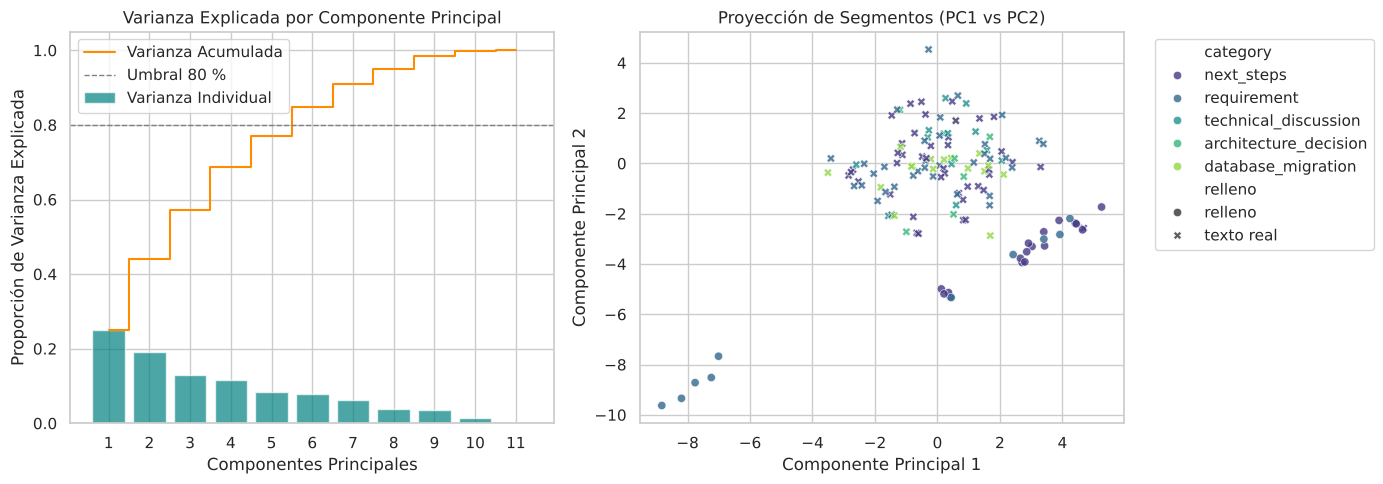


--- Resultados de PCA ---
Variables de entrada: ['end_sec', 'segment_duration_sec', 'text_length', 'word_count', 'avg_word_length', 'duration_min', 'num_speakers', 'rel_pos', 'gap_prev_sec', 'tech_term_count', 'phase_ord'] | componentes retenidos: 6 (Kaiser sugiere 4)
Componente 1: Varianza Explicada = 25.04%, Acumulada = 25.04%
Componente 2: Varianza Explicada = 19.02%, Acumulada = 44.06%
Componente 3: Varianza Explicada = 13.02%, Acumulada = 57.07%
Componente 4: Varianza Explicada = 11.62%, Acumulada = 68.70%
Componente 5: Varianza Explicada = 8.38%, Acumulada = 77.07%
Componente 6: Varianza Explicada = 7.74%, Acumulada = 84.82%


In [ ]:
# --- 7. REDUCCIÓN DE DIMENSIONALIDAD (PCA) ---
# PCA (extracción, no supervisado) sobre las continuas/ordinales que pasaron varianza y correlación.
# Las binarias no se incluyen: una descomposición de varianza lineal no es adecuada para 0/1 raras.
pca_cols = pca_pool
assert len(pca_cols) >= 2, "PCA requiere al menos 2 variables"
pca_full = PCA(random_state=RANDOM_STATE).fit(df_scaled.loc[train, pca_cols])
cum_full = np.cumsum(pca_full.explained_variance_ratio_)
# Criterio: componentes necesarios para >= 80 % de varianza (mínimo 2 para poder graficar)
n_comp = max(2, int(np.argmax(cum_full >= 0.80)) + 1)
kaiser = int((pca_full.explained_variance_ > 1).sum())     # regla de Kaiser (autovalor > 1) como contraste

pca = PCA(n_components=n_comp, random_state=RANDOM_STATE).fit(df_scaled.loc[train, pca_cols])
X_pca = pca.transform(df_scaled[pca_cols])                  # se proyectan TODOS los segmentos
explained_var = pca.explained_variance_ratio_
cum_var = np.cumsum(explained_var)

# Visualización
plt.figure(figsize=(14, 5))

# Gráfico de varianza explicada acumulada
plt.subplot(1, 2, 1)
k_all = len(pca_full.explained_variance_ratio_)
plt.bar(range(1, k_all + 1), pca_full.explained_variance_ratio_, alpha=0.7, color='teal', label='Varianza Individual')
plt.step(range(1, k_all + 1), cum_full, where='mid', color='darkorange', label='Varianza Acumulada')
plt.axhline(0.80, color='gray', ls='--', lw=1, label='Umbral 80 %')
plt.xlabel('Componentes Principales')
plt.ylabel('Proporción de Varianza Explicada')
plt.title('Varianza Explicada por Componente Principal')
plt.xticks(range(1, k_all + 1))
plt.legend()

# Proyección de Segmentos en el espacio PCA
plt.subplot(1, 2, 2)
df_pca_plot = pd.DataFrame(X_pca, columns=[f'PC{i}' for i in range(1, n_comp + 1)])
df_pca_plot['category'] = df_merged['expected_category'].values
df_pca_plot['relleno'] = np.where(placeholder, 'relleno', 'texto real')

sns.scatterplot(data=df_pca_plot, x='PC1', y='PC2', hue='category', style='relleno', palette='viridis', alpha=0.8)
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.title('Proyección de Segmentos (PC1 vs PC2)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

print("\n--- Resultados de PCA ---")
print(f"Variables de entrada: {pca_cols} | componentes retenidos: {n_comp} (Kaiser sugiere {kaiser})")
for idx, (var, cum) in enumerate(zip(explained_var, cum_var), 1):
    print(f"Componente {idx}: Varianza Explicada = {var:.2%}, Acumulada = {cum:.2%}")

In [ ]:
# --- 8. CARGAS FACTORIALES DEL PCA ---
loadings = pd.DataFrame(pca.components_.T, columns=[f'PC{i}' for i in range(1, n_comp + 1)], index=pca_cols)
print("\n--- Cargas Factoriales de las Variables ---")
display(loadings.round(3))


--- Cargas Factoriales de las Variables ---


,PC1,PC2,PC3,PC4,PC5,PC6
end_sec,0.409,0.392,-0.103,0.109,0.115,-0.203
segment_duration_sec,-0.057,-0.024,-0.009,0.707,0.519,0.236
text_length,-0.173,0.528,-0.132,0.118,-0.369,0.077
word_count,-0.405,0.441,-0.228,0.065,-0.056,-0.200
avg_word_length,0.419,-0.103,0.202,0.010,-0.353,0.423
duration_min,-0.123,0.250,0.538,0.379,-0.205,0.068
num_speakers,-0.170,0.175,0.612,-0.188,0.024,0.208
rel_pos,0.426,0.379,0.018,-0.210,0.020,-0.088
gap_prev_sec,0.440,0.222,0.066,0.104,0.291,-0.038
tech_term_count,-0.111,0.249,-0.299,-0.296,0.254,0.761


### **Interpretación de los Componentes Principales (Cargas Factoriales)**

El PCA se ajustó con las 11 variables numéricas/ordinales que pasaron los filtros. Para llegar al 80 % de varianza se necesitan **6 componentes (84.8 %)**; la regla de Kaiser (autovalor > 1) sugiere 4 (68.7 %). Es decir, el PCA reduce de 11 a 6 variables, pero no comprime de forma radical: las variables aportan información poco redundante entre sí (el scree plot cae de forma gradual, sin un "codo" claro).

1. **PC1 (25.0 %):** cargas positivas en `gap_prev_sec` (0.44), `rel_pos` (0.43), `avg_word_length` (0.42) y `end_sec` (0.41), y negativa en `word_count` (-0.41). Describe la **ubicación temporal dentro de la sesión**, con segmentos tardíos, con pausas y con palabras largas pero poco numerosas frente a segmentos tempranos y verbosos.
2. **PC2 (19.0 %):** cargas positivas en `text_length` (0.53), `word_count` (0.44), `end_sec` (0.39) y `rel_pos` (0.38). Describe el **volumen de texto**.
3. **En el gráfico PC1 vs PC2 se ve el efecto de lote:** los segmentos de relleno forman grupos separados del resto (por su texto muy corto y su plantilla), lo que confirma que conviene tratarlos aparte.
4. **Decisión:** como las 4 variables seleccionadas con ANOVA y chi-cuadrado ya reducen de 30 a 4 con una interpretación directa, el PCA se conserva como **representación comprimida alternativa** (`PC1…PC6`) y para diagnóstico, no como sustituto. Las interpretaciones de los componentes son descriptivas: con 66 segmentos no son estables.


In [ ]:
# --- 9. VERIFICACIONES FINALES Y EXPORTACIÓN DE LA MATRIZ DE CARACTERÍSTICAS ---
final_features = sel_num + sel_bin
X_final = pd.concat([df_scaled[sel_num], df_encoded[sel_bin].astype(float)], axis=1)
pcs = pd.DataFrame(X_pca, columns=[f'PC{i}' for i in range(1, n_comp + 1)], index=df_encoded.index)

checks = {
    "141 segmentos originales -> 139 válidos + 2 excluidos": len(df_segments) == 141 and len(df_segments_clean) == 139 and len(df_segments_excluded) == 2,
    "Ninguna característica deriva de la variable objetivo": not any('expected_category' in f for f in final_features),
    "La matriz final no tiene NaN ni infinitos": bool(np.isfinite(X_final.values).all() and np.isfinite(pcs.values).all()),
    "Escalador ajustado solo con el conjunto de ajuste (media 0 allí)": bool(df_scaled.loc[train, cand_num].mean().abs().max() < 1e-9),
    "El PCA se ajustó con el conjunto de ajuste": pca.n_samples_ == int(train.sum()),
    "Todas las particiones tienen datos": bool(dev.sum() > 0 and val.sum() > 0 and tst.sum() > 0),
    "Sin segmentos duplicados por segment_id": df_encoded['segment_id'].is_unique,
}
for name, ok in checks.items():
    print(("✔ " if ok else "✘ ") + name)
assert all(checks.values()), "Alguna verificación falló: no se exporta"

# Comprobación de no-fuga: en validation/test las variables NO tienen media 0 (no se reajustó con ellos)
print("\nMedia de las variables escaladas por partición (solo el ajuste debe ser ~0):")
display(pd.DataFrame({'ajuste': df_scaled.loc[train, sel_num].mean(), 'validation': df_scaled.loc[val, sel_num].mean(),
                      'test': df_scaled.loc[tst, sel_num].mean()}).round(3))

export = pd.concat([df_encoded[['segment_id', 'session_id', 'dataset_split', 'is_placeholder']], y.rename('target'), X_final, pcs], axis=1)
export.to_csv('features_equipo11.csv', index=False)
print(f"\nMatriz exportada: features_equipo11.csv -> {export.shape[0]} filas x {export.shape[1]} columnas")
print(f"Reducción: {len(cand_num) + len(bin_cols)} candidatas -> {len(final_features)} seleccionadas -> {n_comp} componentes (sobre las {len(pca_cols)} continuas)")

✔ 141 segmentos originales -> 139 válidos + 2 excluidos
✔ Ninguna característica deriva de la variable objetivo
✔ La matriz final no tiene NaN ni infinitos
✔ Escalador ajustado solo con el conjunto de ajuste (media 0 allí)
✔ El PCA se ajustó con el conjunto de ajuste
✔ Todas las particiones tienen datos
✔ Sin segmentos duplicados por segment_id

Media de las variables escaladas por partición (solo el ajuste debe ser ~0):


,ajuste,validation,test
tech_term_count,-0.0,-0.351,-0.252



Matriz exportada: features_equipo11.csv -> 139 filas x 15 columnas
Reducción: 30 candidatas -> 4 seleccionadas -> 6 componentes (sobre las 11 continuas)


## **Conclusiones Generales de la Fase de Preparación de Datos bajo CRISP-ML(Q)**

La fase de Preparación de los datos cubre sus cinco tareas y las verificaciones de calidad que CRISP-ML(Q) agrega a cada fase. El resultado es una matriz de características reproducible (`features_equipo11.csv`) lista para pasar al Modelado.

1. **Selección de datos y verificación de calidad.** Se partió de 30 sesiones y 141 segmentos. Se excluyeron justificadamente `SEG017` (`end_sec` < `start_sec`) y `SEG028` (sin texto), con lo que quedan 139 segmentos válidos. Se imputó `UNKNOWN_SPEAKER` / `UNKNOWN_ROLE` conservando una bandera, se eliminó el markup HTML de 3 segmentos y se comprobó con `assert` que no quedó ninguno. Los 36 textos repetidos se conservaron por ser segmentos distintos de un corpus por plantillas.
2. **Construcción de datos.** Se crearon 7 características de dominio (`rel_pos`, `gap_prev_sec`, 4 indicadores léxicos y `tech_term_count`), y la codificación se justificó por tipo: ordinal para la fase, one-hot para el rol y separación de la variable objetivo para evitar fuga de información.
3. **Formato de los datos.** Yeo-Johnson corrigió la asimetría de 5 variables (|skew| bajó de 0.84–1.26 a 0.03–0.24) y el z-score igualó las escalas. Todo se ajustó **solo** con el conjunto de ajuste (66 segmentos de 16 sesiones de development); validation y test solo se transforman.
4. **Reducción de complejidad.** Los filtros llevaron de 30 candidatas a 4 (`has_obligation`, `has_commitment`, `has_number`, `tech_term_count`), con control de pruebas múltiples. El PCA sobre las 11 numéricas retiene 84.8 % de la varianza con 6 componentes.
5. **Garantías de calidad y reproducibilidad.** Las verificaciones automáticas de la sección 9 pasan, el notebook corre de principio a fin sin intervención y la matriz final se exporta solo si todas se cumplen.

**Riesgos y límites que pasan a la fase de Modelado**
- **Corpus sintético y por plantillas.** Los indicadores léxicos separan casi perfectamente las categorías porque los textos se generaron con plantillas. Su desempeño con conversaciones reales es una hipótesis, no un resultado.
- **Efecto de lote.** SEG001–SEG030 son relleno en español y solo tienen 2 de las 5 categorías. Se marcó con `is_placeholder` y no participa en los ajustes; se recomienda reemplazarlo por segmentos reales.
- **Desbalance y tamaño.** `architecture_decision` tiene solo 6 segmentos, y test tiene 11 segmentos de 3 sesiones. Los intervalos de las métricas serán muy amplios. Los segmentos están agrupados por sesión, por lo que conviene validar por sesión.
- **Consistencia del conjunto de referencia.** Las 141 preguntas del gold standard apuntan a segmentos y sesiones existentes, pero 2 apuntan a segmentos excluidos (`SEG017`, `SEG028`), 2 no tienen revisor, solo cubren 2 de las 5 categorías y todas son de plantilla (61 caracteres). En RAG, 1 de 24 documentos está vacío y 1 está duplicado. La afirmación de que el conjunto es "100 % consistente" se debe matizar con estos puntos antes de usarlo en la evaluación de fidelidad (`faithfulness`).
- **Pendiente.** Reemplazar las preguntas de plantilla por preguntas concretas con revisión humana documentada y definir el protocolo de validación y prueba para el asistente RAG (Fase 3 de CRISP-ML(Q)).
